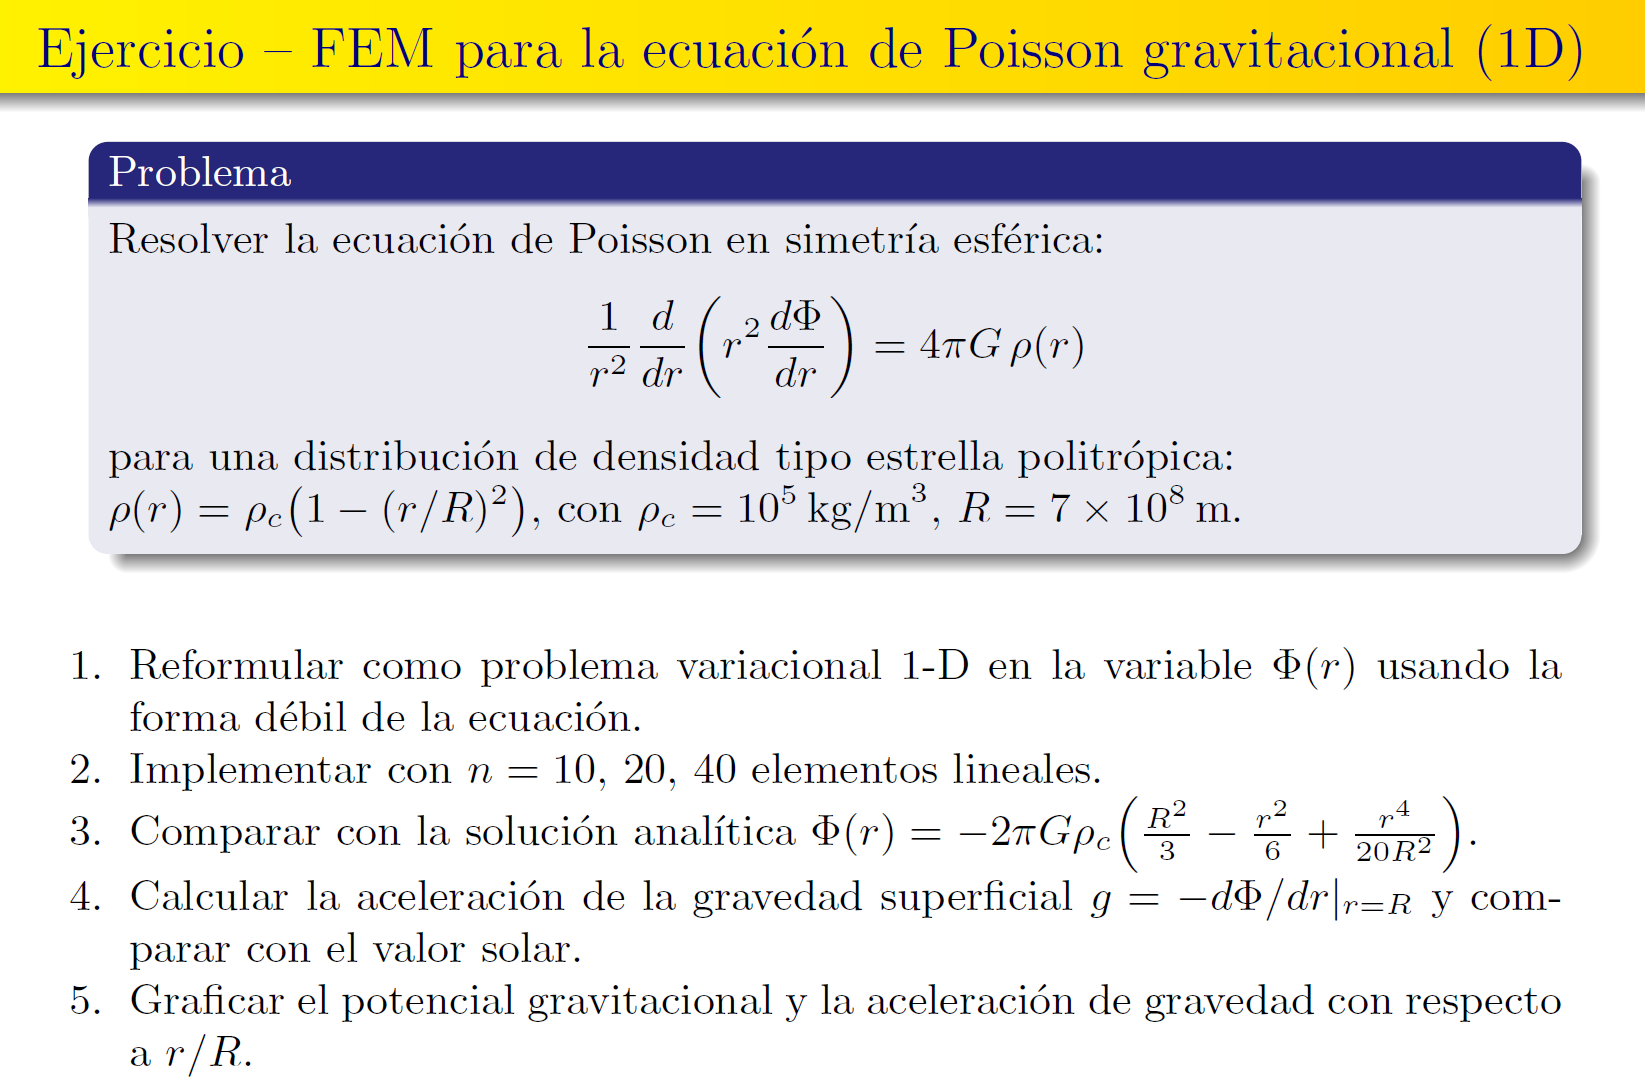

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros del problema
R = 7.0e8              
rho_c = 1.0e5         
G = 6.6743e-11         
Phi_R = 0.0            # Condición de frontera de Dirichlet
n = 20                
h = R / n             
r = np.linspace(0, R, n + 1) 

In [13]:
#Ensamblaje de la matriz

N_nodes = n + 1
K = np.zeros((N_nodes, N_nodes))
f = np.zeros(N_nodes)

for k in range(n):
    r_k = r[k]
    r_k1 = r[k+1]
    
    K_e_val = (r_k1**3 - r_k**3) / (3.0 * h**2)
    K_e = K_e_val * np.array([[1.0, -1.0], [-1.0, 1.0]])
    
    I2 = (r_k1**3 - r_k**3) / 3.0
    I3 = (r_k1**4 - r_k**4) / 4.0
    I4 = (r_k1**5 - r_k**5) / 5.0
    I5 = (r_k1**6 - r_k**6) / 6.0
    
    term0 = ((r_k1 * I2 - I3) / h) - ((r_k1 * I4 - I5) / (h * R**2))
    term1 = ((I3 - r_k * I2) / h) - ((I5 - r_k * I4) / (h * R**2))
    
    f_e0 = -4.0 * np.pi * G * rho_c * term0
    f_e1 = -4.0 * np.pi * G * rho_c * term1
    
    K[k, k] += K_e[0, 0]
    K[k, k+1] += K_e[0, 1]
    K[k+1, k] += K_e[1, 0]
    K[k+1, k+1] += K_e[1, 1]
    
    f[k] += f_e0
    f[k+1] += f_e1

# Aplicación de la condición de frontera en r = R (Dirichlet)
f[n-1] = f[n-1] - K[n-1, n] * Phi_R
K[n-1, n] = 0.0
K[n, n-1] = 0.0
K[n, n] = 1.0
f[n] = Phi_R

In [14]:
# Resolución del sistema lineal
N_sys = N_nodes
M_aug = np.column_stack((K, f)).astype(float)

# Eliminación hacia adelante con pivoteo parcial
for i in range(N_sys):
    max_fila = i + np.argmax(abs(M_aug[i:, i]))
    if i != max_fila:
        temp = M_aug[i].copy()
        M_aug[i] = M_aug[max_fila]
        M_aug[max_fila] = temp
        
    for j in range(i + 1, N_sys):
        factor = M_aug[j, i] / M_aug[i, i]
        M_aug[j, i:] = M_aug[j, i:] - factor * M_aug[i, i:]

# Sustitución hacia atrás para obtener el vector de potencial Phi
Phi = np.zeros(N_sys)
for i in range(N_sys - 1, -1, -1):
    Phi[i] = (M_aug[i, -1] - np.sum(M_aug[i, i+1:N_sys] * Phi[i+1:N_sys])) / M_aug[i, i]

In [15]:
#Post-procesamiento, solución analítica y cálculo de la gravedad superficial

r_mid = (r[:-1] + r[1:]) / 2.0
Phi_exact = -2.0 * np.pi * G * rho_c * ((R**2 / 3.0) - (r**2 / 6.0) + (r**4 / (20.0 * R**2)))

# Cálculo de la aceleración de la gravedad FEM (g = -dPhi/dr)
g_fem = np.zeros(n)
for k in range(n):
    g_fem[k] = -(Phi[k+1] - Phi[k]) / h

g_surface = -(Phi[n] - Phi[n-1]) / h
g_exact_R = 4.0 * np.pi * G * rho_c * (-R / 3.0 + R**3 / (5.0 * R**2))

print("Aceleración superficial (FEM):", g_surface)
print("Aceleración superficial (Analítica):", g_exact_R)

Aceleración superficial (FEM): -8184.491950308517
Aceleración superficial (Analítica): -7828.027889865627


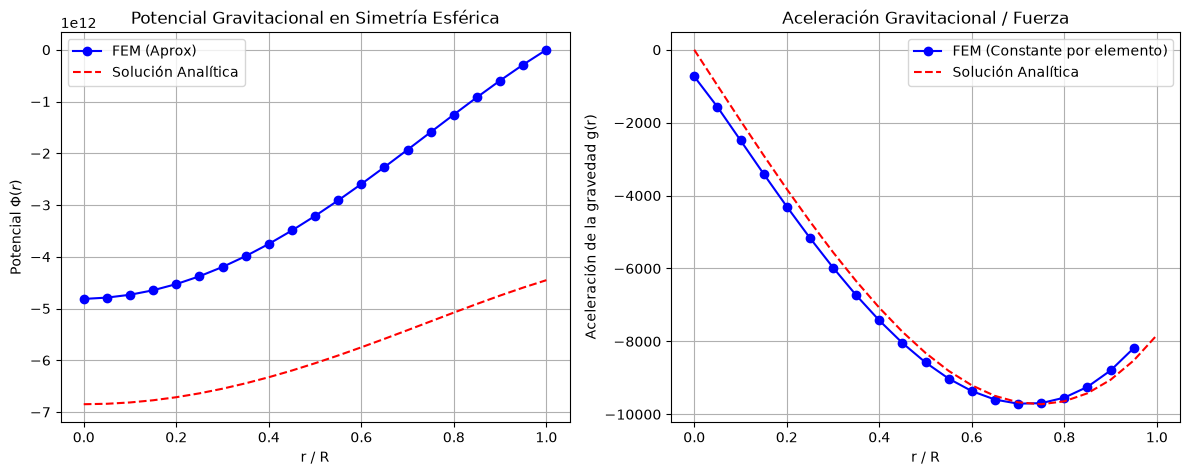

In [16]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(r / R, Phi, 'bo-', label='FEM (Aprox)')
plt.plot(r / R, Phi_exact, 'r--', label='Solución Analítica')
plt.xlabel('r / R')
plt.ylabel(r'Potencial $\Phi(r)$')
plt.title('Potencial Gravitacional en Simetría Esférica')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
g_analitica_plot = 4.0 * np.pi * G * rho_c * (-r / 3.0 + r**3 / (5.0 * R**2))
plt.plot(r[:-1] / R, g_fem, 'bo-', label='FEM (Constante por elemento)')
plt.plot(r / R, g_analitica_plot, 'r--', label='Solución Analítica')
plt.xlabel('r / R')
plt.ylabel('Aceleración de la gravedad g(r)')
plt.title('Aceleración Gravitacional / Fuerza')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()